In [1]:
# Rebuild the final model from 02
# We redo it here because in 03, we fitted the model on data with last visit hidden to test predictions. Here we want to describe every girl as well as possible, so we use all her visits. In the next step we'll take each girl's two personal numbers out of this model and LOOK FOR GROUPS.

import pandas as pd, numpy as np, matplotlib.pyplot as plt
import statsmodels.formula.api as smf

#Load the cleaned data
df = pd.read_csv("../data/fev1_clean.csv")

# Prepare the 2 predictions
df["lh_c"]  = np.log(df["height"]) - np.log(1.5)
df["age10"] = (df["age"] - 12) / 10

#Fit the model
m3 = smf.mixedlm("log_fev1 ~ lh_c + bs(age, df=4, lower_bound=6, upper_bound=19)", data=df,
                 groups=df["id"], re_formula="~age10").fit(reml=False, method=["powell", "lbfgs"])
print("converged:", m3.converged)

converged: True


/var/folders/wd/6lvzbdln5zs0vfn0nyhwwvdr0000gn/T/ipykernel_50336/2908849044.py:16: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  groups=df["id"], re_formula="~age10").fit(reml=False, method=["powell", "lbfgs"])


In [2]:
# Get each girl's 2 personal number
# m3.random_effects is a dictionary: for each girl's id, her two estimated deviations from the average
# pd.DataFrame... turns it into a table with one row per girl (orient="index" means "the dictionary keys become rows")
# "level" = how far she sits above or below the average curve. It's on the log scale, so +0.10 means about 10% higher FEV1 than an average girl of the same height and age
# "speed" = how much faster or slower she matures than average. It's per decade of age, so +0.07 means about 0.7% more growth per year
# n_visits = records how much data each girl contributed


re = m3.random_effects                                   # one entry per girl
girls = pd.DataFrame.from_dict(re, orient="index")       # turn it into a table
girls.columns = ["level", "speed"]
girls.index.name = "id"
girls["n_visits"] = df.groupby("id").size()

print(girls.shape)
girls.describe().round(3)

(300, 3)


,level,speed,n_visits
count,300.000,300.000,300.000
mean,-0.000,-0.000,6.647
std,0.100,0.048,3.852
min,-0.728,-0.197,1.000
25%,-0.058,-0.021,3.000
50%,0.003,0.002,7.000
75%,0.072,0.027,10.000
max,0.270,0.146,12.000


Reading the table:

1. Means are 0, as expected: random effects are deviations from the average, so they balance out.

2. level: SD 0.10. Girls typically sit about ±10% above or below the average curve, and this is consistent over time. The range goes from −0.73 to +0.27.

3. speed: SD 0.048. Girls differ in maturation speed too, but there's something to notice here. In Lesson 2, the model estimated the true spread of speeds at √0.006 ≈ 0.077. The individual estimates here are only half as spread out. Why? Shrinkage. For a girl with 1–3 visits, there's almost no information about her personal speed, so the model pulls her estimate towards 0 (the average). That's sensible for prediction, but it matters for clustering, as you'll see in the plot.

4. The minimum level is −0.728. exp(−0.728) ≈ 0.48, meaning about half the FEV1 of an average girl of the same size. I'd bet this is girl 197, the 0.50 L measurement we flagged in Lesson 1. Even after shrinkage, one extreme value gives her an extreme level. An outlier like this can distort clustering, so we'll keep an eye on it.

In [3]:
# Who is at the extremes?
print(girls.sort_values("level").head(3))

        level     speed  n_visits
id                               
197 -0.727920  0.029657         1
223 -0.264787 -0.013607         4
69  -0.233087  0.009838         9


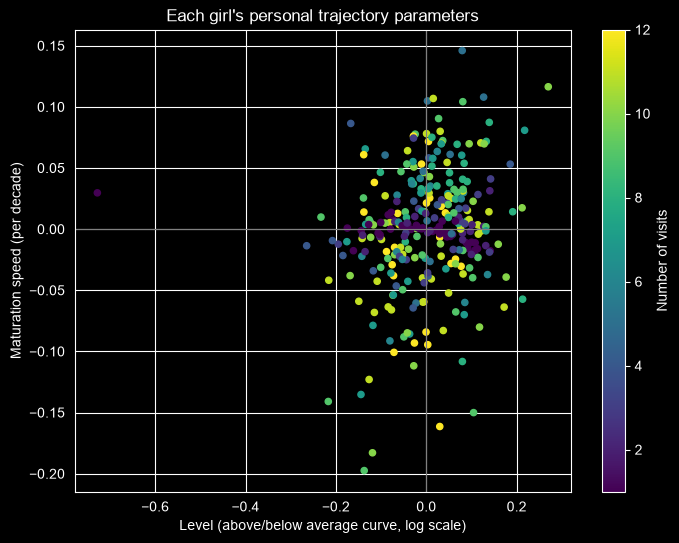

In [4]:
# Plot level against speed
fig, ax = plt.subplots(figsize=(8, 6))
sc = ax.scatter(girls["level"], girls["speed"], c=girls["n_visits"], cmap="viridis", s=20)
fig.colorbar(sc, label="Number of visits")
ax.axhline(0, color="grey", lw=0.8); ax.axvline(0, color="grey", lw=0.8)
ax.set_xlabel("Level (above/below average curve, log scale)")
ax.set_ylabel("Maturation speed (per decade)")
ax.set_title("Each girl's personal trajectory parameters"); plt.show()

Reading the plot:

1. The purple dots (1–3 visits) are squashed onto the horizontal zero line = shrinkage. With so few visits, the model can't tell how fast these girls mature, so it gives them the average speed: 0. Their "speed" isn't a measurement, just a default value.

Why that matters: if we clustered all 300 girls, k-means could create a group of "average-speed girls" that is really just "girls with little data". That would be an artefact, not a phenotype. **So we'll cluster only girls with enough visits.**

2. The lone dot far to the left (level ≈ −0.73) is dark purple, so it's a single-visit girl. Almost certainly girl 197 and her 0.50 L test. Dropping girls with few visits removes her automatically.

3. The yellow and green dots (many visits) form one roundish cloud, with no obvious gaps between groups. That's an honest early warning: **there may be no natural clusters, just a continuum of girls who are a bit higher or lower, a bit faster or slower. k-means will always return groups when you ask for them, so we need evidence (silhouette and stability) before believing them.**

In [5]:
# Keep only girls with enough data

from sklearn.preprocessing import StandardScaler

# At least 5 visits (assumption)
sub = girls[girls["n_visits"] >= 5].copy()
print(len(sub), "girls with at least 5 visits")

# Standardize: k-means groups points by distance. `level` varies about twice as much as speed (SD 0.10 vs 0.05), so without rescaling, distances would be dominated by level and speed would barely count. StandardScaler rescales each column to mean 0 and SD 1, so both count equally.
X = StandardScaler().fit_transform(sub[["level", "speed"]])
print(X.mean(axis=0).round(2), X.std(axis=0).round(2))

196 girls with at least 5 visits
[0. 0.] [1. 1.]


In [6]:
# 2 to 5 clusters
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

for k in range(2, 6):
    # n_clusters = splits the girls into k groups, so that each girl is close to her group's centre
    # n_init = tries 20 different starting positions and keeps the best, because k-means can get stuck on a poor solution
    km = KMeans(n_clusters=k, n_init=20, random_state=42).fit(X)

    # silhouette_score = for each girl, how much closer she is to her own group than to the next nearest group, averaged over all girls
    print(f"k = {k}   silhouette = {silhouette_score(X, km.labels_):.3f}")




k = 2   silhouette = 0.390
k = 3   silhouette = 0.365
k = 4   silhouette = 0.355
k = 5   silhouette = 0.364


In [7]:
# null benchmark
# Splitting a single round blob in two also gives a silhouette around 0.3–0.4. So we need a reference: simulate data with no clusters, but the same spread and correlation as ours, and see what silhouette k-means gets on it.
# k-means always fin dclusters, even in random data with no real groups To check "is my result better than cwhat pure chance would give?",
# - generate random data with no structure
# - run k-means on ot and record how tight clusters are
# - compare with your real data: if your real clusters are much tighter than the random ones, the groups are real

rng = np.random.default_rng(0)
cov = np.cov(X.T)                     # spread and correlation of our real data

null_scores = []
for _ in range(100):
    X_null = rng.multivariate_normal([0, 0], cov, size=len(X))   # one blob, no groups
    km = KMeans(n_clusters=2, n_init=10, random_state=0).fit(X_null)
    null_scores.append(silhouette_score(X_null, km.labels_))

print(f"Real data (k=2): 0.390")
print(f"No-cluster data:  mean {np.mean(null_scores):.3f}, 95th percentile {np.percentile(null_scores, 95):.3f}")

Real data (k=2): 0.390
No-cluster data:  mean 0.362, 95th percentile 0.389


There's no convincing evidence of distinct trajectory phenotypes in this cohort. Girls vary smoothly: a bit higher or lower, a bit faster or slower, without falling into separate types.

It fits the data:

* Healthy girls from one population. There's no group with a disease or a different exposure that might create a separate trajectory type.
* The random effects are shrunk estimates (as you saw in the plot), which pulls girls towards the centre and blurs any separation.
* Only two dimensions (level and speed). In the real PhD, with preterm status, breath metabolomics and exposures, distinct groups are more plausible.

In [8]:
# Stability check
# Even if the groups aren't distinct, we can ask whether the k = 2 split is reproducible. If we redrew the sample, would girls end up in the same group?

from sklearn.metrics import adjusted_rand_score

base = KMeans(n_clusters=2, n_init=20, random_state=42).fit(X)
rng = np.random.default_rng(1)
aris = []
for b in range(200):
    idx = rng.integers(0, len(X), len(X))                     # bootstrap sample of girls
    kmb = KMeans(n_clusters=2, n_init=10, random_state=b).fit(X[idx])
    aris.append(adjusted_rand_score(base.labels_, kmb.predict(X)))

print(f"Stability (ARI): mean {np.mean(aris):.2f}, 5th percentile {np.percentile(aris, 5):.2f}")


Stability (ARI): mean 0.94, 5th percentile 0.77


A high ARI mean that the results are **reproducible** not that the groups are real.

So here we have a **stable way of dividing a continuum**, not two separate types of girls. This is the stability-isn't-sufficient point in action: stability alone would have suggested two real phenotypes, and only the null benchmark showed otherwise.



In [9]:
# Describing the 2 halves of the continuum

sub["group"] = base.labels_
print(sub["group"].value_counts())
print(sub.groupby("group")[["level", "speed", "n_visits"]].mean().round(3))

group
1    113
0     83
Name: count, dtype: int64
       level  speed  n_visits
group                        
0     -0.071 -0.038     9.458
1      0.059  0.028     8.885


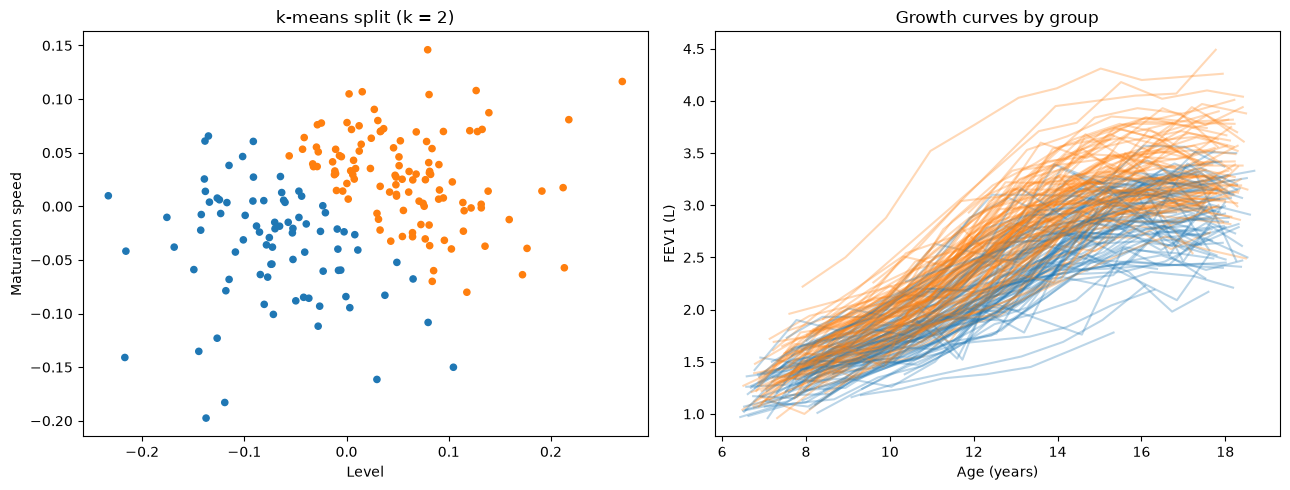

In [10]:
plt.style.use("default")

colors = {0: "tab:blue", 1: "tab:orange"}
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Left: the split in the level–speed plane
axes[0].scatter(sub["level"], sub["speed"], c=sub["group"].map(colors), s=20)
axes[0].set(xlabel="Level", ylabel="Maturation speed", title="k-means split (k = 2)")

# Right: the same girls' measured growth curves
for gid, g in df[df["id"].isin(sub.index)].groupby("id"):
    axes[1].plot(g["age"], g["fev1"], color=colors[sub.loc[gid, "group"]], alpha=0.3)
axes[1].set(xlabel="Age (years)", ylabel="FEV1 (L)", title="Growth curves by group")
plt.tight_layout(); plt.savefig("../figures/phenotypes.png", dpi=150, bbox_inches="tight"); plt.show()

# Summary

## Phenotyping summary
Each girl's random intercept (level) and random age slope (maturation speed) were taken
from the final mixed model (m3, fitted on all visits).

- Girls with 1–3 visits had speed estimates shrunk to ~0 (too little information), so
  clustering used the 196 girls with ≥5 visits. Both variables were standardised.
- k-means (k = 2–5) gave weak structure: silhouette 0.355–0.390, best at k = 2.
- **Null benchmark:** clustering simulated single-cloud data with the same covariance
  gave silhouette 0.362 on average (95th percentile 0.389). The real data (0.390) is no
  better, so there is **no evidence of distinct trajectory phenotypes**; girls vary along
  a continuum.
- The k = 2 split is nonetheless reproducible (bootstrap ARI 0.94, 5th percentile 0.77)
  and can be used descriptively: "higher and faster" (n = 113; level +0.06, speed +0.03)
  vs "lower and slower" (n = 83; level −0.07, speed −0.04). Visit counts were similar.
- Girls who start lower also mature more slowly, so their FEV1 falls further behind
  during adolescence (tracking with divergence).
- Lessons: stability alone does not prove clusters exist; a null benchmark is needed.
  Distinct phenotypes may emerge with more informative variables (e.g. preterm birth,
  exposures, biomarkers) or with latent class trajectory models (LCMM).